
# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Шилов Алексей Вячеславович
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

clean = pd.read_parquet("clean_data.parquet")

In [13]:

sns.set_theme(style="whitegrid")

COLORS = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974", "#64B5CD"]
CHANNEL_COLORS = {"Карта": "#4C72B0", "Токен": "#55A868", "СБП": "#C44E52", "Онлайн-банк": "#8172B2"}
SEG_ORDER = ["Массовый", "Зарплатный", "Премиальный", "Private"]

## 1. Главное

1. Пользоваться картами стали реже на пятую часть: 2.98 -> 2.33 операции на клиента в месяц (−21.6%), из первой половины 2024 в первую половину 2025.
2. Клиенты из банка не уходят: активных за полугодие даже больше — 4 859 -> 5 609.
   Падает именно пользование картой: месячный охват 73.5% → 68.3%, частота 4.04 -> 3.41 операции в месяц.
3. Падение сосредоточено в массовом сегменте: по карте −38.6…−38.1% — вдвое сильнее, чем в остальных сегментах (−23.9…−5.2%).
4. Выделены 4 группы кампании, каждая — правилом по признакам клиента: 1 794 человека в лимите 2 000, с согласием на коммуникацию — 1 586, под каждую группу — свой оффер (раздел 5).

In [14]:

from IPython.display import display

N_CLIENTS = 5619  


def sp(x):
    return f"{x:,}".replace(",", " ")


clean["month"] = clean.txn_datetime.dt.to_period("M")
h1 = clean[clean.txn_datetime.dt.month <= 6].copy()
h1["half"] = np.where(h1.txn_datetime.dt.year == 2024, "y24", "y25")
card = h1[h1.channel == "Карта"]


def half_ops(data):
    """Операции клиента за H1 2024 и H1 2025 широкой таблицей."""
    return (data.groupby(["client_id", "half"]).size().unstack(fill_value=0)
                .reindex(columns=["y24", "y25"], fill_value=0))


def month_stats(data, n_total):
    g = data.groupby("month").agg(ops=("txn_id", "size"), act=("client_id", "nunique"))
    g["per_client"] = g.ops / n_total
    g["reach"] = g.act / n_total * 100
    g["intensity"] = g.ops / g.act
    g["half"] = np.where(g.index.year == 2024, "H1 2024", "H1 2025")
    return g.groupby("half")[["per_client", "reach", "intensity"]].mean()


means = month_stats(card, N_CLIENTS).reindex(["H1 2024", "H1 2025"])
a, b = means.iloc[0], means.iloc[1]
active = h1.groupby("half").client_id.nunique().reindex(["y24", "y25"])

summary_tbl = pd.DataFrame(
    {"H1 2024": [f"{a.per_client:.2f}", f"{a.reach:.1f}%", f"{a.intensity:.2f}", sp(active.y24)],
     "H1 2025": [f"{b.per_client:.2f}", f"{b.reach:.1f}%", f"{b.intensity:.2f}", sp(active.y25)],
     "изменение": [f"{(b.per_client / a.per_client - 1) * 100:+.1f}%",
                   f"{b.reach - a.reach:+.1f} п.п.",
                   f"{(b.intensity / a.intensity - 1) * 100:+.1f}%",
                   f"{active.y25 - active.y24:+}"]},
    index=["операций по карте на клиента в месяц", "месячный охват картой",
           "операций на платящего картой в месяц", "активных клиентов за полугодие"],
).rename_axis("показатель")
display(summary_tbl)

campaign = pd.read_csv("campaign_list.csv", encoding="utf-8")
clients_ref = pd.read_csv("data/clients.csv", encoding="utf-8").drop_duplicates("client_id", keep="first")
consented_n = int(clients_ref.set_index("client_id").marketing_opt_in
                  .reindex(campaign.client_id).eq("Да").sum())

print(f"Информация о кампании:\nГрупп: {campaign.group.nunique()}, клиентов: {campaign.client_id.nunique()}, клиентов с согласием на маркетинг: {consented_n}")

,H1 2024,H1 2025,изменение
показатель,,,
операций по карте на клиента в месяц,2.98,2.33,-21.6%
месячный охват картой,73.5%,68.3%,-5.2 п.п.
операций на платящего картой в месяц,4.04,3.41,-15.7%
активных клиентов за полугодие,4 859,5 609,+750


Информация о кампании:
Групп: 4, клиентов: 1794, клиентов с согласием на маркетинг: 1586



## 2. Контекст

Департамент розничных продуктов готовит кампанию по возврату активности по картам.

Бюджет — до 2 000 клиентов.
Кампания идёт группами: под каждую группу готовится своё сообщение. Групп от 3 до 5, и в каждой не меньше 150 человек.
Писать можно только клиентам, которые согласны на маркетинг.

Отчёт отвечает на вопросы руководителя: насколько и у кого упала активность,
за счёт чего — чтобы понимать, что этим людям предлагать, и кого в кампанию брать не нужно.



## 3. Данные и ограничения

Период: 2024-01-01 — 2025-06-30.
В очищенном справочнике 5 619 клиентов (5 674 строк в сыром файле), в очищенной таблице 582 364 успешные операции от 5 616 из них.
В исходном файле было 637 851 операций; из расчёта исключены:
дубли (1 500), отклонённые и возвраты (20 117),
операции в евро и долларах (2 446), даты вне периода (80)
и операции 381 клиента, которого нет в справочнике (31 344 операций) —
у них нет данных о сегменте и городе.

Метрика активности — число успешных операций по Карте за месяц, делённое на всех 5 619 клиентов справочника.
Знаменатель — весь справочник, не только держатели карт.
Сравниваются первые полугодия 2024 и 2025 года, потому что данные обрываются на июне 2025
Метрика не увидит снижение средней суммы операции, так как она оценивает число операций.
Уход клиента в наличные или в другой банк метрика также не увидит — она заметит лишь уменьшение числителя, а причину (перестал платить вовсе или перешёл в другой канал) различить не сможет

Чего в данных нет: второй половины 2025 года, причин отклонения транзакций, лимитов карт.


In [15]:
log = pd.read_csv("cleaning_log.csv", encoding="utf-8")
row = log[log["issue"] == "клиенты без записи в справочнике"].iloc[0]
n_raw_clients = len(pd.read_csv("data/clients.csv", encoding="utf-8"))
chk = card.groupby("half").amount.mean().reindex(["y24", "y25"])

facts_tbl = pd.DataFrame(
    {"значение": [f"{clean.txn_datetime.min().date()} — {clean.txn_datetime.max().date()}",
                  f"{sp(len(clean))} операций",
                  f"{sp(clean.client_id.nunique())} из 5 619",
                  f"{sp(n_raw_clients)} строк → 5 619",
                  f"{row.value_before.split()[0]} клиентов, {sp(int(row.n_rows))} операций",
                  f"{sp(int(round(chk.y24)))} → {sp(int(round(chk.y25)))} руб. "
                  f"({(chk.y25 / chk.y24 - 1) * 100:+.1f}%)"]},
    index=["период данных", "операций после очистки", "клиентов с операцией",
           "справочник: сырой → очищенный", "клиенты вне справочника (исключены)",
           "средний чек по карте: H1 2024 → H1 2025"],
).rename_axis("показатель")
display(facts_tbl)

n = [637851, 636351, 616234, 613788, 613708, len(clean)]
funnel = pd.DataFrame(
    {"шаг": ["загружено как есть", "убраны дубли txn_id", "только статус успешно",
            "только валюта RUB", "период 2024-01-01 .. 2025-06-30", "клиент есть в справочнике"],
     "осталось": n,
     "исключено": ["—"] + [x - y for x, y in zip(n, n[1:])]}).set_index("шаг")
display(funnel)

,значение
показатель,
период данных,2024-01-01 — 2025-06-30
операций после очистки,582 364 операций
клиентов с операцией,5 616 из 5 619
справочник: сырой → очищенный,5 674 строк → 5 619
клиенты вне справочника (исключены),"381 клиентов, 31 344 операций"
средний чек по карте: H1 2024 → H1 2025,1 956 → 1 781 руб. (-8.9%)


,осталось,исключено
шаг,,
загружено как есть,637851,—
убраны дубли txn_id,636351,1500
только статус успешно,616234,20117
только валюта RUB,613788,2446
период 2024-01-01 .. 2025-06-30,613708,80
клиент есть в справочнике,582364,31344



## 4. Находки


### 4.1. Клиенты стали реже платить картой, а число активных клиентов только увеличилось

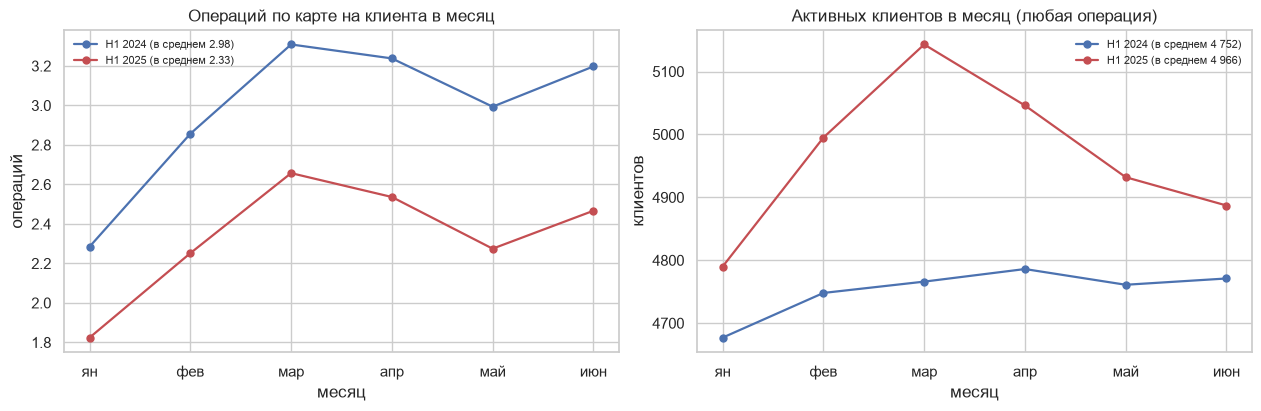

In [16]:
per_m = card.groupby("month").agg(ops=("txn_id", "size"))
per_m["per_client"] = per_m.ops / N_CLIENTS
all_act = h1.groupby("month").client_id.nunique()

MONTH_NAMES = ["ян", "фев", "мар", "апр", "май", "июн"]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), layout="constrained")
for ax, series, title, ylab, fmt in [
    (axes[0], per_m["per_client"], "Операций по карте на клиента в месяц", "операций", "{:.2f}"),
    (axes[1], all_act.astype(float), "Активных клиентов в месяц (любая операция)", "клиентов", "{:,.0f}"),
]:
    s24 = series[series.index.year == 2024]
    s25 = series[series.index.year == 2025]
    fmt_ = lambda v: fmt.format(v).replace(",", " ")
    ax.plot(range(1, 7), s24.values, marker="o", ms=5, lw=1.6, color=COLORS[0],
            label=f"H1 2024 (в среднем {fmt_(s24.mean())})")
    ax.plot(range(1, 7), s25.values, marker="o", ms=5, lw=1.6, color=COLORS[2],
            label=f"H1 2025 (в среднем {fmt_(s25.mean())})")
    ax.set_title(title)
    ax.set_ylabel(ylab)
    ax.set_xlabel("месяц")
    ax.set_xticks(range(1, 7), MONTH_NAMES)
    ax.legend(fontsize=8, frameon=False)
plt.show()

Активных клиентов стало больше — 4 859 -> 5 609 за полугодие, в среднем за месяц 4 752 -> 4 966
По графикам можно понять, что кампании необходимо привлечь клиентов к оплате картой, а не возвращать ушедших.

### 4.2. Падение в массовом сегменте не объясняется наличием или отсутствием приложения

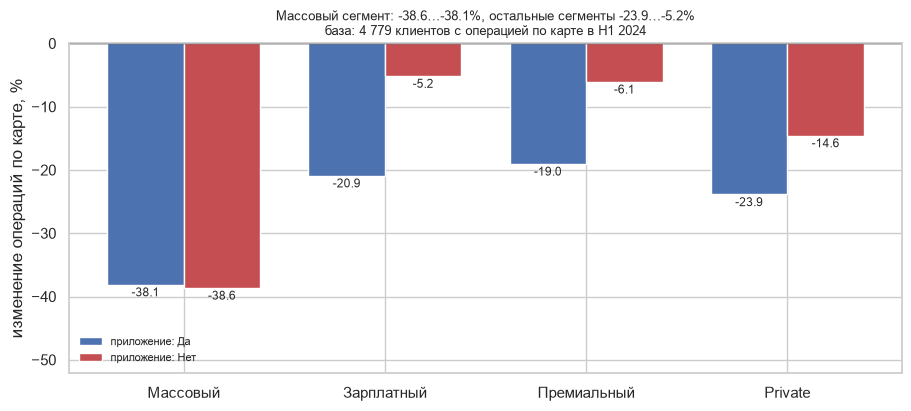

In [17]:
tab = pd.DataFrame(index=np.sort(clean.client_id.unique()))
tab["segment"] = clean.groupby("client_id").segment.first()
tab["app"] = clean.groupby("client_id").has_mobile_app.first()
tab = tab.join(half_ops(card).add_prefix("card_"))

seg_full = tab[tab.card_y24 > 0].groupby(["segment", "app"]).apply(
    lambda g: pd.Series({"клиентов": len(g),
                         "карта, %": (g.card_y25.mean() / g.card_y24.mean() - 1) * 100}),
    include_groups=False).reset_index()

pct = seg_full.set_index(["segment", "app"])["карта, %"]
mass, others = pct.xs("Массовый"), pct.drop("Массовый")

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
x = np.arange(len(SEG_ORDER))
w = 0.38
for i, app in enumerate(["Да", "Нет"]):
    vals = seg_full[seg_full.app == app].set_index("segment").reindex(SEG_ORDER)["карта, %"]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=f"приложение: {app}", color=[COLORS[0], COLORS[2]][i])
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8.5)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x, SEG_ORDER)
ax.set_ylabel("изменение операций по карте, %")
ax.set_title(f"Массовый сегмент: {mass.min():+.1f}…{mass.max():+.1f}%, остальные сегменты "
             f"{others.min():+.1f}…{others.max():+.1f}%\n"
             f"база: {sp(int((tab.card_y24 > 0).sum()))} клиентов с операцией по карте в H1 2024",
             fontsize=9.5)
ax.legend(fontsize=8, frameon=False)
ax.set_ylim(min(others.min(), mass.min()) * 1.35, 0)
plt.show()

Падение сосредоточено в одном сегменте: массовый −38.6% без приложения и −38.1% с приложением.
Остальные сегменты просели заметно меньше: от −23.9% (Private с приложением) до −5.2% (зарплатные без приложения).
Значит, кампанию надо строить вокруг массового сегмента - он показывает наихудшее падение.

### 4.3. У массовых с приложением — три разных падения: одежда, переход на токен и сжатие всех трат

группа 3 в H1 2025: платят картой 80% клиентов, совмещают карту и токен 80%, карту потеряли совсем 43


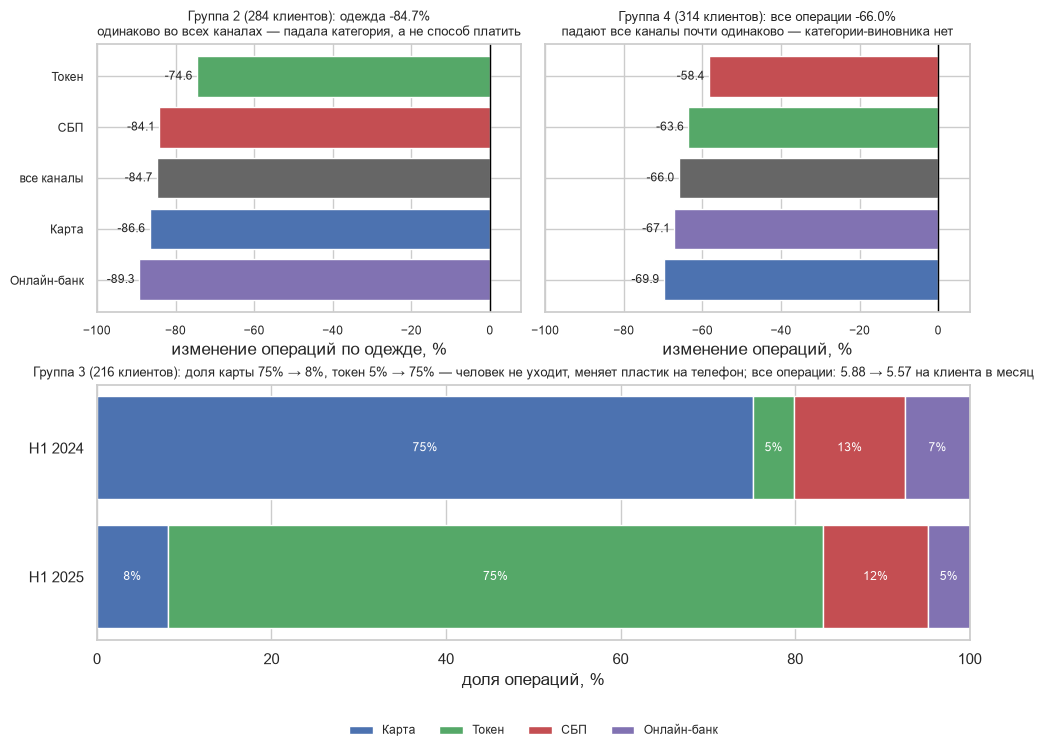

In [18]:

grp = campaign.set_index("client_id")["group"]

ids2 = grp[grp == "2. Массовые с приложением, одежда"].index
cloth = h1[(h1.client_id.isin(ids2)) & (h1.category == "Одежда и обувь")]
rows = []
for ch in ["Карта", "Онлайн-банк", "СБП", "Токен", None]:
    d = cloth if ch is None else cloth[cloth.channel == ch]
    g = half_ops(d).reindex(ids2, fill_value=0)
    rows.append({"канал": ch if ch else "все каналы",
                 "одежда, %": (g.y25.sum() / g.y24.sum() - 1) * 100})
g2_tbl = pd.DataFrame(rows).set_index("канал")

ids4 = grp[grp == "4. Массовые с приложением, резкое падение"].index
d4 = h1[h1.client_id.isin(ids4)]
rows4 = []
for ch in ["Карта", "Онлайн-банк", "СБП", "Токен", None]:
    dd = d4 if ch is None else d4[d4.channel == ch]
    g = half_ops(dd).reindex(ids4, fill_value=0)
    b = g[g.y24 > 0]
    rows4.append({"канал": "все операции" if ch is None else ch,
                  "все, %": (b.y25.mean() / b.y24.mean() - 1) * 100})
g4_tbl = pd.DataFrame(rows4).set_index("канал")

ids3 = grp[grp == "3. Массовые с приложением, ушли в токен"].index
d3 = h1[h1.client_id.isin(ids3)]
rows3 = []
for name, d in [("Карта", d3[d3.channel == "Карта"]),
                ("Токен", d3[d3.channel == "Токен"]),
                ("Все операции", d3)]:
    g = half_ops(d).reindex(ids3, fill_value=0)
    rows3.append({"показатель": name, "H1 2024": g.y24.mean() / 6, "H1 2025": g.y25.mean() / 6})
g3_tbl = pd.DataFrame(rows3).set_index("показатель")

g3c = half_ops(d3[d3.channel == "Карта"]).reindex(ids3, fill_value=0)
g3t = half_ops(d3[d3.channel == "Токен"]).reindex(ids3, fill_value=0)
print(f"группа 3 в H1 2025: платят картой {(g3c.y25 > 0).mean() * 100:.0f}% клиентов, "
      f"совмещают карту и токен {((g3c.y25 > 0) & (g3t.y25 > 0)).mean() * 100:.0f}%, "
      f"карту потеряли совсем {int(((g3c.y24 > 0) & (g3c.y25 == 0)).sum())}")

sh = d3.pivot_table(index="half", columns="channel", values="txn_id", aggfunc="size", fill_value=0)
sh = (sh.div(sh.sum(axis=1), axis=0) * 100).reindex(["y24", "y25"])
sh.index = ["H1 2024", "H1 2025"]

fig = plt.figure(figsize=(9.8, 7.4), layout="constrained")
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.95])

ax = fig.add_subplot(gs[0, 0])
s = g2_tbl["одежда, %"].sort_values()
bars = ax.barh(s.index, s.values, color=[CHANNEL_COLORS.get(i, "#666666") for i in s.index])
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8.5)
ax.axvline(0, color="black", lw=1)
ax.set_xlim(-100, 8)
ax.set_title(f"Группа 2 ({len(ids2)} клиентов): одежда {g2_tbl.loc['все каналы', 'одежда, %']:+.1f}%\n"
             "одинаково во всех каналах — падала категория, а не способ платить", fontsize=9.5)
ax.set_xlabel("изменение операций по одежде, %")
ax.tick_params(labelsize=8.5)

ax = fig.add_subplot(gs[0, 1])
s4 = g4_tbl["все, %"].sort_values()
bars = ax.barh(s4.index, s4.values, color=[CHANNEL_COLORS.get(i, "#666666") for i in s4.index])
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8.5)
ax.axvline(0, color="black", lw=1)
ax.set_xlim(-100, 8)
ax.set_title(f"Группа 4 ({len(ids4)} клиентов): все операции {g4_tbl.loc['все операции', 'все, %']:+.1f}%\n"
             "падают все каналы почти одинаково — категории-виновника нет", fontsize=9.5)
ax.set_xlabel("изменение операций, %")
ax.tick_params(labelsize=8.5)
ax.set_yticklabels([])

ax = fig.add_subplot(gs[1, :])
left = np.zeros(len(sh))
for ch in ["Карта", "Токен", "СБП", "Онлайн-банк"]:
    vals = sh[ch].values
    ax.barh(sh.index, vals, left=left, color=CHANNEL_COLORS[ch], label=ch)
    for i, (l, v) in enumerate(zip(left, vals)):
        if v > 4:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5, color="white")
    left = left + vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("доля операций, %")
ax.set_title(f"Группа 3 ({len(ids3)} клиентов): доля карты {sh.loc['H1 2024', 'Карта']:.0f}% → {sh.loc['H1 2025', 'Карта']:.0f}%, "
             f"токен {sh.loc['H1 2024', 'Токен']:.0f}% → {sh.loc['H1 2025', 'Токен']:.0f}% — человек не уходит, меняет пластик на телефон; "
             f"все операции: {g3_tbl.loc['Все операции', 'H1 2024']:.2f} → {g3_tbl.loc['Все операции', 'H1 2025']:.2f} на клиента в месяц",
             fontsize=9.5)
ax.legend(fontsize=8.5, ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.42))
plt.show()

У массовых с приложением падение идёт тремя отдельными линиями.
Первая — одежда и обувь: группа 2 стала их сильно меньше покупать — операции по категории упали на −84.7%
примерно одинаково во всех каналах. Этой группе предлагать надо одежду и обувь, способ оплаты не влияет.
Вторая — оплата телефоном вместо карты: в группе 3 доля карты в операциях упала с 75% до 8%, доля токена выросла с 5% до 75%,
а общее число операций почти не изменилось: 5.88 -> 5.57 на клиента в месяц.
Третья — группа 4: падают все каналы сразу и почти одинаково.

## 5. Группы для кампании

In [19]:
def hcol(data, name):
    """Операции клиента за H1 2024 и H1 2025 с префиксом канала/категории."""
    return half_ops(data).add_prefix(name + "_")


act = pd.DataFrame(index=np.sort(clean.client_id.unique()))
act["segment"] = clients_ref.set_index("client_id").segment.reindex(act.index)
act["app"] = clients_ref.set_index("client_id").has_mobile_app.reindex(act.index)
act = (act.join(hcol(h1[h1.channel == "Карта"], "card"))
          .join(hcol(h1[h1.channel == "Токен"], "tok"))
          .join(hcol(h1, "all"))
          .join(hcol(h1[h1.category == "Одежда и обувь"], "cl"))
          .fillna(0).astype({"card_y24": "int", "card_y25": "int", "tok_y24": "int", "tok_y25": "int",
                             "all_y24": "int", "all_y25": "int", "cl_y24": "int", "cl_y25": "int"}))
act["consent"] = clients_ref.set_index("client_id").marketing_opt_in.reindex(act.index).eq("Да")


def pct(g, name):
    b = g[g[name + "_y24"] > 0]
    return (b[name + "_y25"].mean() / b[name + "_y24"].mean() - 1) * 100 if len(b) else np.nan


rows = []
for label, g in act.groupby(grp):
    rows.append({"группа": label, "клиентов": len(g), "с согласием": int(g.consent.sum()),
                 "карта, %": pct(g, "card"), "все операции, %": pct(g, "all"),
                 "одежда, %": pct(g, "cl"), "токен, %": pct(g, "tok")})
grp_tbl = pd.DataFrame(rows).set_index("группа")
grp_tbl.loc["ИТОГО"] = {"клиентов": grp_tbl["клиентов"].sum(), "с согласием": grp_tbl["с согласием"].sum(),
                        **{c: np.nan for c in ["карта, %", "все операции, %", "одежда, %", "токен, %"]}}
display(grp_tbl.round(1))

r2 = act[(act.segment == "Массовый") & (act.app == "Да") & (act.card_y24 > 0) & (act.cl_y24 > 0) &
         (act.cl_y25 / act.cl_y24 < 0.5) & (act.all_y25 / act.all_y24 >= 0.5)]
r34 = act[(act.segment == "Массовый") & (act.app == "Да") & (act.card_y24 > 0) &
          (act.card_y25 / act.card_y24 < 0.5)]
print(f"Пересечение Г2 и Г3/Г4: {len(r2.index.intersection(r34.index))} клиентов — по правилу относим их в Г2")


,клиентов,с согласием,"карта, %","все операции, %","одежда, %","токен, %"
группа,,,,,,
1. Массовые без приложения,980,862,-38.6,-39.7,-54.0,-36.0
"2. Массовые с приложением, одежда",284,251,-32.4,-18.2,-84.7,24.8
"3. Массовые с приложением, ушли в токен",216,193,-89.8,-5.3,9.7,1076.4
"4. Массовые с приложением, резкое падение",314,280,-69.9,-66.0,-67.7,-63.6
ИТОГО,1794,1586,NaN,NaN,NaN,NaN


Пересечение Г2 и Г3/Г4: 76 клиентов — по правилу относим их в Г2


**Группа 1 — массовые без мобильного приложения** (980 клиентов, из них 862 с согласием на маркетинг).
Кто: сегмент «Массовый», приложения нет, в первой половине 2024 была хотя бы одна операция по карте.
Падает все: карта −38.6% и все операции вместе −39.7% — человек стал реже проводить транзакции.
Приложения нет, поэтому маркетинг проводить надо через звонок или SMS.
Что предлагать: кэшбэк или бонусные баллы за покупки в повседневных категориях — «Продукты», «Аптеки», «Транспорт».

**Группа 2 — массовые с приложением, у которых провалилась одежда** (284 клиента, 251 с согласием на маркетинг).
Кто: «Массовый» с приложением, были покупки одежды в первой половине 2024, во второй из них покупки одежды упали больше чем вдвое, а общие траты — меньше чем вдвое 
Падение локальное: одежда −84.7%, и почти одинаково во всех каналах — пропала именно конкретная категория.
Что предлагать: скидку или кэшбэк на одежду и обувь, через push-уведомления в приложении или SMS.

**Группа 3 — массовые с приложением, ушедшие с карты на токен** (216 клиентов, 193 с согласием на маркетинг).
Кто: «Массовый» с приложением, карта упала сильнее чем наполовину, токен-операций в первой половине 2025 стало больше.
Операции по карте упали на −89.8%, токен-операции выросли на 1076.4%, а общее число операций почти не изменилось (−5.3%).
Что предлагать: короткий опрос о причине перехода на токен — с бонусом за ответы; бонус за покупку картой — точечно 43 клиентам, которые полностью отказались от использования карты; бонус за комбинирование карты и токена в месяце — так платят 80% группы. Для маркетинга использовать приложение.

**Группа 4 — массовые с приложением, резкое падение** (314 клиентов, 280 с согласием на маркетинг).
Кто: «Массовый» с приложением, карта упала сильнее чем наполовину, токен при этом не вырос.
Падает все: карта −69.9%, все операции −66.0%, одежда −67.7%, токен −63.6%.
Что предлагать: бонус за 2–3 покупки, кэшбэк на любые категории, персональное предложение.

Если клиент подходит сразу под 2 и под 3/4, он отнесён в группу 2.

## 6. Кого не включаем и почему
В кампанию не идёт 4 033 клиента из 5 619.

1. Вне массового сегмента — 2 765 человек. Их карта падает слабее (−14.9% против −38.3%):
   люди активны, им нечего возвращать.
2. Массовые без операций по карте в первой половине 2024 — 371 человек. Нет данных, с которыми
   можно было бы сравнить их активность в первой половине 2025, поэтому не включаем в кампанию
3. Массовые с приложением и картой, но не вошедшие в группы — 689 человек.
   У всех карта упала меньше чем на 50%, и число таких клиентов слишком велико - не включаем в кампанию.
4. Попали в группу, но нет согласия на маркетинг - 208 человек. Таким клиентам нельзя ничего предлагать,
   поэтому не включаем их в кампанию.


In [20]:
reg = clients_ref.set_index("client_id")[["segment", "has_mobile_app", "marketing_opt_in"]].join(
    half_ops(card), how="left").fillna({"y24": 0, "y25": 0})

mass = reg[reg.segment == "Массовый"]
non_mass = reg[reg.segment != "Массовый"]
mass_no_card = mass[mass.y24 == 0]
notin = ((reg.segment == "Массовый") & (reg.y24 > 0) & (reg.has_mobile_app == "Да") &
         ~reg.index.isin(grp.index))
mass_app_notin = reg[notin]

nm = non_mass[non_mass.y24 > 0]
ms = mass[mass.y24 > 0]
nm_pct = (nm.y25.mean() / nm.y24.mean() - 1) * 100
ms_pct = (ms.y25.mean() / ms.y24.mean() - 1) * 100
soft = int((mass_app_notin.y25 / mass_app_notin.y24 >= 0.5).sum())

opt = clients_ref.set_index("client_id").marketing_opt_in
consented = int(opt.reindex(grp.index).eq("Да").sum())
no_consent_groups = int((opt.reindex(grp.index) != "Да").sum())

cats = pd.DataFrame(
    {"клиентов": [len(non_mass), len(mass_no_card), len(mass_app_notin), no_consent_groups],
     "почему не берём": [
         f"карта падает в {abs(ms_pct / nm_pct):.1f} раза слабее: {nm_pct:+.1f}% против {ms_pct:+.1f}% в массовом",
         "нет операций по карте в H1 2024 — нечего возвращать",
         f"карта упала меньше чем на 50% у всех ({soft} из {len(mass_app_notin)}) — обычные колебания",
         "в группе, но согласия на коммуникацию нет — писать нельзя"]},
    index=["вне массового сегмента", "массовые без карты в H1 2024",
           "массовые с приложением и картой, но не в группах",
           "в группах, но без согласия"]).rename_axis("категория")

total_not = len(non_mass) + len(mass_no_card) + len(mass_app_notin) + no_consent_groups
not_campaign = len(reg) - consented
assert total_not == not_campaign, "категории не покрывают всех вне кампании"
cats.loc["ИТОГО вне кампании"] = {"клиентов": not_campaign,
                                  "почему не берём": f"сверка: {sp(len(reg))} клиентов минус {sp(consented)} с согласием"}
display(cats)

,клиентов,почему не берём
категория,,
вне массового сегмента,2765,карта падает в 2.6 раза слабее: -14.9% против ...
массовые без карты в H1 2024,371,нет операций по карте в H1 2024 — нечего возвр...
"массовые с приложением и картой, но не в группах",689,карта упала меньше чем на 50% у всех (689 из 6...
"в группах, но без согласия",208,"в группе, но согласия на коммуникацию нет — пи..."
ИТОГО вне кампании,4033,сверка: 5 619 клиентов минус 1 586 с согласием


## 7. Что проверили и что не подтвердилось
Проверяли, не объясняется ли падение чем-то, кроме сегмента и характера трат. Ни одна гипотеза не подтвердилась:

1. **«Клиенты ушли из банка».** Не подтвердилось: активных клиентов стало больше — 4 859 → 5 609 (раздел 4.1).
2. **«В Нижнем Новгороде падение сильнее».** Не подтвердилось: по городам массового сегмента карта падает примерно одинаково — Санкт-Петербург −41.2%, Нижний Новгород −39.7%, Москва −37.8%, Новосибирск −37.2%, Казань −36.8%, Екатеринбург −34.8%; худший город — не Нижний Новгород
3. **«Активность пенсионеров 75+ падает сильнее».** Не подтвердилось: 75+ дают −39.3%, столько же, сколько 60–74, хуже всех — группа <30 (−53.7%).
4. **«Всё объясняет уровень лояльности».** Не подтвердилось: внутри массового сегмента все уровни лояльности падают одинаково, −37.0…−39.7%.
5. **«Всё объясняет тип карты».** Не подтвердилось: внутри массового сегмента все типы карт −38.2…−38.7%.


In [21]:
attrs = clients_ref.set_index("client_id")[["segment", "loyalty_tier", "card_type", "birth_date"]]
city = clean.groupby("client_id").city.first()
reg2 = attrs.join(half_ops(card), how="left").fillna({"y24": 0, "y25": 0})
reg2["city"] = city.reindex(reg2.index)
reg2["age"] = (pd.Timestamp("2025-06-30") - pd.to_datetime(reg2["birth_date"])).dt.days / 365.25
reg2["age_group"] = pd.cut(reg2["age"], [0, 30, 45, 60, 75, 100],
                           labels=["<30", "30-44", "45-59", "60-74", "75+"], right=False)


def pc(g):
    b = g[g.y24 > 0]
    return (b.y25.mean() / b.y24.mean() - 1) * 100 if len(b) else np.nan


mass2 = reg2[reg2.segment == "Массовый"]

city_tbl = mass2.groupby("city").apply(pc, include_groups=False).sort_values().round(1).to_frame("карта, %")
display(city_tbl.T)

age_tbl = mass2.groupby("age_group", observed=True).apply(pc, include_groups=False).round(1).to_frame("карта, %")
display(age_tbl.T)

lz_tbl = mass2.groupby("loyalty_tier").apply(pc, include_groups=False).round(1).to_frame("карта, %")
display(lz_tbl.T)

ct_tbl = mass2.groupby("card_type").apply(pc, include_groups=False).round(1).to_frame("карта, %")
display(ct_tbl.T)

city,Санкт-Петербург,Нижний Новгород,Москва,Новосибирск,Казань,Екатеринбург
"карта, %",-41.2,-39.7,-37.8,-37.2,-36.8,-34.8


age_group,<30,30-44,45-59,60-74,75+
"карта, %",-53.7,-42.5,-34.9,-39.3,-39.3


loyalty_tier,Базовый,Золото,Платина,Серебро
"карта, %",-38.0,-37.0,-37.1,-39.7


card_type,Дебетовая,Кредитная,Премиальная
"карта, %",-38.2,-38.7,-38.4


## 8. Приложение

### 8.1. Сводка журнала изменений


In [22]:
log2 = pd.read_csv("cleaning_log.csv", encoding="utf-8")
summ = (log2.groupby("action")
            .agg(решений=("field", "size"), строк_затронуто=("n_rows", "sum"),
                 поля=("field", lambda s: ", ".join(sorted(set(s)))))
            .sort_values("строк_затронуто", ascending=False))
display(summ)

,решений,строк_затронуто,поля
action,,,
исправление типа,1,637851,txn_datetime
нормализация,2,55011,"category, city"
ограничено,4,53987,"client_id, currency, status, txn_datetime"
оставлено,6,6983,"amount, app_last_login, birth_date, monthly_in..."
дедупликация,2,1555,"client_id, txn_id"
"исправлено, умножено на 1000",1,170,monthly_income
замена значения,1,61,monthly_income


### 8.2. Методика

**Очистка.** Исходные 637 851 операций сокращаются:
удаление дублей по txn_id -> только status = успешно -> только currency = RUB ->
период 2024-01-01 .. 2025-06-30 -> клиент присутствует в справочнике. Итог 582 364 операции.
Справочник клиентов 5 674 строк свёрнут к 5 619 клиентам, действуя по правилу "при дубликате client_id оставляем только первую строку".

**Окна.** первая половина 2024 = январь–июнь 2024 (база), первая половина 2025 = январь–июнь 2025 (оценка).
Месячный фильтр: txn_datetime.dt.month <= 6.

**Метрика активности.** Для каждого месяца (month): operations(month) — успешные операции по карте в month,
per_client(M) = operations(M) / 5619. Значение полугодия — среднее per_client по шести месяцам.
 Изменение — (оценка − база) / база.

**Правила групп** (все поля — из справочника и операций):
- Группа 1: segment = Массовый и has_mobile_app = Нет и card_y24 > 0 (card_y24 - число операций по карте за первую половину 2024);
- Группа 2: segment = Массовый и has_mobile_app = Да и card_y24 > 0 и clothes_y24 > 0 (clothes_y24 - число операций в категории «Одежда и обувь» за первую половину 2024)
  и clothes_ratio < 0.5 и total_ratio >= 0.5 (ratio = число операций за первую половину 2025 к первой половине 2024, по clothes - одежда, по total - все операции);
- Группа 3: segment = Массовый и has_mobile_app = Да и card_y24 > 0 и card_ratio < 0.5 и token_y25 > token_y24 (token_y24, token_y25 - число токен-операций за первую половину 2024 и 2025);
- Группа 4: segment = Массовый и has_mobile_app = Да и card_y24 > 0 и card_ratio < 0.5 и token_y25 <= token_y24.
Клиент, попадающий под несколько правил, относится в группу с меньшим номером: Г2 выше Г3/Г4 (76 клиентов).
Порог падения «сильнее чем наполовину» = ratio < 0.5.

**Лимиты.** Не более 2 000 уникальных клиентов (в кампании 1 794), группа не менее 150
(самая малочисленная 216), в рассылку только marketing_opt_in = Да (1 586).

### 8.3. Использование ИИ

ИИ использовался как помощник, решения по данным принимались самостоятельно.

**Для чего:**
1. поддержания единого стиля графиков и форматирования markdown-ячеек
2. очистки и отладки кода, подготовки данных для графиков и таблиц, расчёта метрик
3. поиска ошибок в препроцессинге и упрощения отдельных участков кода.

**Что проверял сам:**
1. что все числа в тексте совпадают с выводом кода при полном прогоне
2. обоснованность предложений убрать выбросы — по итогам проверки выбросы не удалены
3. что графики и таблицы получены исполнением кода из данных, а не вручную.

Выбор метрик, окон данных, правила групп, итоговый состав кампании - мои решения.
Исходные файлы данных (*.csv) ассистенту не пересылались